<a href="https://colab.research.google.com/github/Chaile-Mendez/tp-analisis-labo/blob/Facu/UsoDeRRSS%C2%BFAfectaSentimentalmente%3F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

El uso de redes afecta las realaicones de las estudiante?
Primero, importamos las librerias que vamos a usar, agregamos el dataset correspondiete, y hacemos un conteo de los valores que van a encasillar toda esta pregunta (columna "Relationship_Status")

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("/content/dataset_final")
pareja = df.dropna ()
print(pareja["Relationship_Status"].value_counts())
pareja.head()


Relationship_Status
Single             384
In Relationship    289
Complicated         32
Name: count, dtype: int64


,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
1038,1,19,Female,Undergraduate,Bangladesh,5.2,Instagram,Yes,6.5,6.0,In Relationship
1039,2,22,Male,Graduate,India,2.1,Twitter,No,7.5,8.0,Single
1040,3,20,Female,Undergraduate,USA,6.0,TikTok,Yes,5.0,5.0,Complicated
1041,4,18,Male,High School,UK,3.0,YouTube,No,7.0,7.0,Single
1042,5,21,Male,Graduate,Canada,4.5,Facebook,Yes,6.0,6.0,In Relationship


luego, calculamos la media y la mediana de las horas de uso diario "Avg_Daily_Usage_Hours" en función a su situación sentimental.

In [20]:
print(pareja.groupby("Relationship_Status")["Avg_Daily_Usage_Hours"].agg(["mean", "median"]))

                         mean  median
Relationship_Status                  
Complicated          4.721875    4.75
In Relationship      4.930796    4.70
Single               4.926042    4.80


Con los cálculos hechos, sumado al gráfico de abajo, podemos ver que el uso diario de redes sociales son muy parecidos entre, los que estan en pareja, solteros o en una situacion sentimental complicada. Por lo tanto con estos datos no podemos obserbar una que el uso de RRSS afecto en la situacion sentimental de los estudiantes

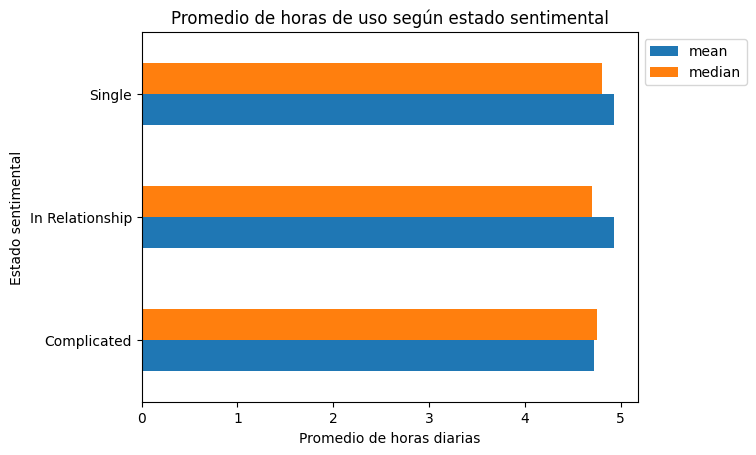

In [21]:
promedios = pareja.groupby("Relationship_Status")["Avg_Daily_Usage_Hours"].agg(["mean", "median"])
promedios.plot(kind="barh")
plt.title("Promedio de horas de uso según estado sentimental")
plt.ylabel("Estado sentimental")
plt.xlabel("Promedio de horas diarias")
plt.legend(loc="upper left",bbox_to_anchor=(1, 1))

plt.show()

In [22]:
print(pareja["Most_Used_Platform"].value_counts())

Most_Used_Platform
Instagram    249
TikTok       154
Facebook     123
WhatsApp      54
Twitter       30
LinkedIn      21
WeChat        15
Snapchat      13
VKontakte     12
LINE          12
KakaoTalk     12
YouTube       10
Name: count, dtype: int64


Aca hacemos una conteo de cuales son las RRSS mas usadas por los estudiantes segun su situacion sentimental, esto para ver si hay una relacion entre las situacion de los alumnos (pareja, soltero, complicado), y el uso de determinada red social

In [23]:
pd.crosstab(pareja["Most_Used_Platform"],pareja["Relationship_Status"],normalize="index").mul(100).round(2)

Relationship_Status,Complicated,In Relationship,Single
Most_Used_Platform,,,
Facebook,0.81,57.72,41.46
Instagram,4.02,37.75,58.23
KakaoTalk,0.00,50.00,50.00
LINE,0.00,0.00,100.00
LinkedIn,23.81,38.10,38.10
Snapchat,30.77,30.77,38.46
TikTok,5.19,29.22,65.58
Twitter,0.00,46.67,53.33
VKontakte,0.00,50.00,50.00


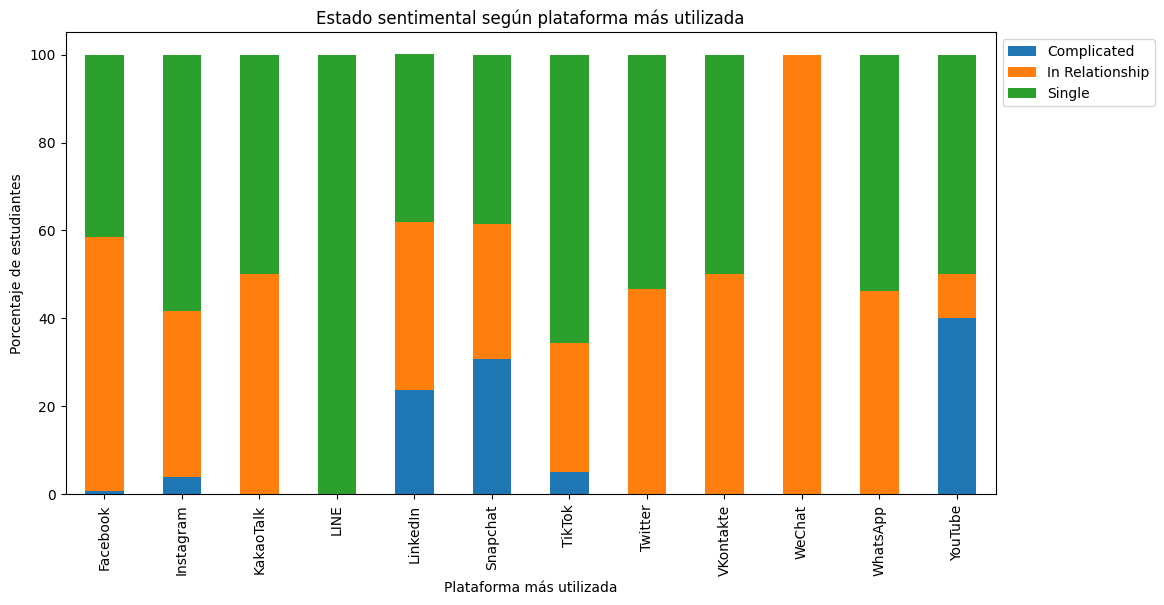

In [24]:
rrss=pd.crosstab(pareja["Most_Used_Platform"],pareja["Relationship_Status"],normalize="index").mul(100).round(2)
rrss.plot(kind="bar",stacked=True,figsize=(12, 6))
plt.title("Estado sentimental según plataforma más utilizada")
plt.xlabel("Plataforma más utilizada")
plt.ylabel("Porcentaje de estudiantes")
plt.legend(loc="upper left",bbox_to_anchor=(1, 1))
plt.show()

In [25]:
masusada=pareja["Most_Used_Platform"].value_counts().nlargest(3).index
#masusada[masusada> 100].index
masusada = pareja[pareja["Most_Used_Platform"].isin(masusada)]
print(masusada["Most_Used_Platform"].value_counts())


Most_Used_Platform
Instagram    249
TikTok       154
Facebook     123
Name: count, dtype: int64


Como el dataset tenia datos de algunos lugares donde se usan plataformas con pocas muestras, decidimos hacer el analisis sobre las mas usadas, Instagram, TikTok y Facebook

In [45]:
pareja["Most_Used_Platform"].value_counts()
pareja

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
1038,1,19,Female,Undergraduate,Bangladesh,5.2,Instagram,Yes,6.5,6.0,In Relationship
1040,3,20,Female,Undergraduate,USA,6.0,TikTok,Yes,5.0,5.0,Complicated
1042,5,21,Male,Graduate,Canada,4.5,Facebook,Yes,6.0,6.0,In Relationship
1043,6,19,Female,Undergraduate,Australia,7.2,Instagram,Yes,4.5,4.0,Complicated
1046,9,18,Male,High School,Japan,4.0,TikTok,No,6.5,7.0,Single
...,...,...,...,...,...,...,...,...,...,...,...
1735,698,24,Male,Graduate,France,4.8,Facebook,No,7.1,7.0,In Relationship
1736,699,19,Female,Undergraduate,Canada,5.7,Instagram,Yes,6.6,6.0,Single
1738,701,20,Female,Undergraduate,Italy,4.7,TikTok,No,7.2,7.0,In Relationship
1739,702,23,Male,Graduate,Russia,6.8,Instagram,Yes,5.9,4.0,Single


In [46]:
pareja = pareja[pareja["Most_Used_Platform"] != "Twitter"]
pareja = pareja[pareja["Most_Used_Platform"] != "KakaoTalk"]
pareja = pareja[pareja["Most_Used_Platform"] != "LINE"]
pareja = pareja[pareja["Most_Used_Platform"] != "LinkedIn"]
pareja = pareja[pareja["Most_Used_Platform"] != "Snapchat"]
pareja = pareja[pareja["Most_Used_Platform"] != "VKontakte"]
pareja = pareja[pareja["Most_Used_Platform"] != "WeChat"]
pareja = pareja[pareja["Most_Used_Platform"] != "WhatsApp"]
pareja = pareja[pareja["Most_Used_Platform"] != "YouTube"]
pareja.info()


<class 'pandas.core.frame.DataFrame'>
Index: 526 entries, 1038 to 1742
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Student_ID                    526 non-null    int64  
 1   Age                           526 non-null    int64  
 2   Gender                        526 non-null    object 
 3   Academic_Level                526 non-null    object 
 4   Country                       526 non-null    object 
 5   Avg_Daily_Usage_Hours         526 non-null    float64
 6   Most_Used_Platform            526 non-null    object 
 7   Affects_Academic_Performance  526 non-null    object 
 8   Sleep_Hours_Per_Night         526 non-null    float64
 9   Mental_Health_Score           526 non-null    float64
 10  Relationship_Status           526 non-null    object 
dtypes: float64(3), int64(2), object(6)
memory usage: 49.3+ KB


Aca sacamos todas las plataformas que conformaban los dato que parecian escasos para quedarno con las tres antes mencionadas

In [37]:
pd.crosstab(pareja["Most_Used_Platform"],pareja["Relationship_Status"],normalize="index").mul(100).round(2)

Relationship_Status,Complicated,In Relationship,Single
Most_Used_Platform,,,
Facebook,0.81,57.72,41.46
Instagram,4.02,37.75,58.23
TikTok,5.19,29.22,65.58


por ultimo, sacamos el porcentaje de alumnos ya sea, solteros, en pareja o en situacion complicada, en funcion de las redes que usan.
Podemos ver una clara inclinacion por TikTok e Instagram para los soltero, no solo eso, sino que tambien hay un poircentaje mas alto de estudiantres en situacion complicada en esas dos redes sociales.

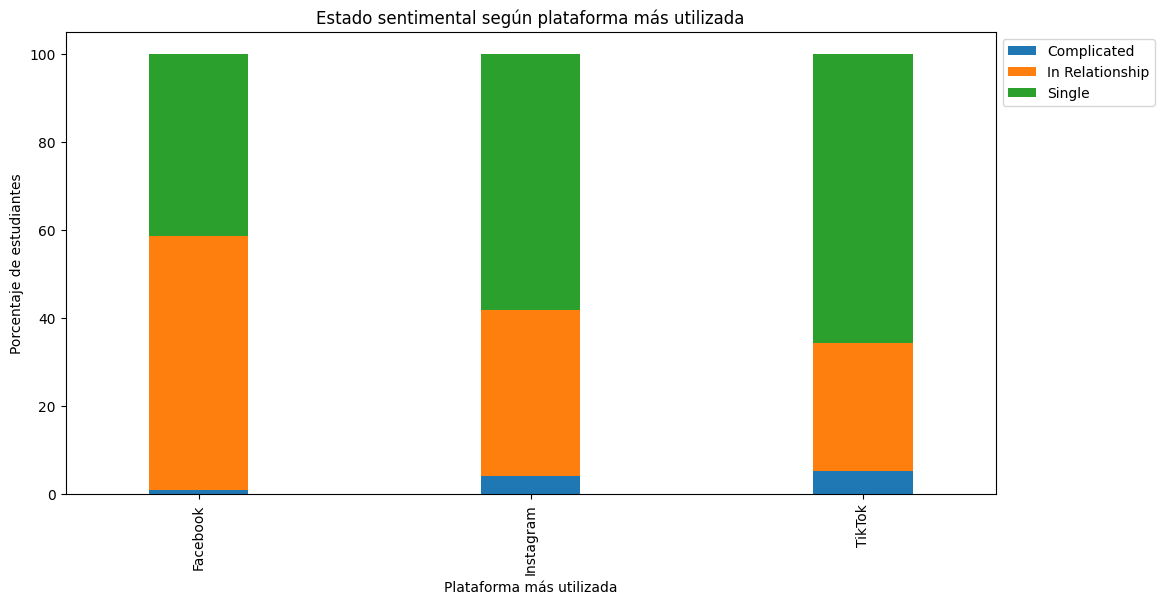

In [44]:
rrss=pd.crosstab(pareja["Most_Used_Platform"],pareja["Relationship_Status"],normalize="index").mul(100).round(2)
rrss.plot(kind="bar",stacked=True,figsize=(12, 6),width=0.3)
plt.title("Estado sentimental según plataforma más utilizada")
plt.xlabel("Plataforma más utilizada")
plt.ylabel("Porcentaje de estudiantes")
plt.legend(loc="upper left",bbox_to_anchor=(1, 1))
plt.show()

Como podemos concluir con estos datos, no parece haber una facto en la vida sentimental de los estudiante por el alto uso de RRSS. Pero si hay una inclinacion por los solteros en el uso de Instagram y TikTok coomo plataforma primaria.